# i. Intro

Author : [cairn-s](https://github.com/cairn-s)

This notebook contains an analysis around injury workplace at 2016, dataset was taken from [Kaggle](https://www.kaggle.com/datasets/robikscube/osha-injury-data-20162021) originated from OSHA 

# ii. Problem Statement and Dataset Description

Data Analyst for Company A Notice that work related accidents are keep happening, especially on industrial area. we will analyze a data about this, so we know how much casualties are reported in hope for reducing casualty. We take a dataset from kaggle which this data contains information of US Work Related Accidents, this data are originated from OSHA, a regulatory agency that ensures safe and healthful working conditions, we will make a questions around our analysis, based on `5W + 1H`:

- How many casualties are reported?
- Which States have the most casualties?
- Which Establishment has the most working hours?
- Whose Establistment responsible for the most casualties?
- What Industry Type has filed the most reports?
- Is There a Relationship Between Working Hours and the Number of Casualties?

# iii. Import Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# iv. Data Load

In [3]:
df_raw = pd.read_csv('injury_data_raw.csv', delimiter=',')
df = df_raw.copy()

## Exploring Data Before Cleaning

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214978 entries, 0 to 214977
Data columns (total 31 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            214978 non-null  int64  
 1   company_name                  199397 non-null  object 
 2   establishment_name            214977 non-null  object 
 3   ein                           0 non-null       float64
 4   street_address                214973 non-null  object 
 5   city                          214974 non-null  object 
 6   state                         214978 non-null  object 
 7   zip_code                      214978 non-null  int64  
 8   naics_code                    214978 non-null  int64  
 9   industry_description          197019 non-null  object 
 10  annual_average_employees      214978 non-null  int64  
 11  total_hours_worked            214975 non-null  float64
 12  no_injuries_illnesses         214978 non-nul

About Dataframe columns:
- `ein` : Stands for Employer Identification Number, assigned by IRS to identify business for Tax purposes<br>
- `naics_code` : Stands for North American Industry Classification System, used to classify business establishment<br>
- `size` : Measure how Big an establishment based on number of employees, with a scale of 1-3, from small to largest:<br>
    - `1` : Establishment has at least 20 Employees
    - `2` : Establishment has Employees between 20 and 249
    - `3` : Establishment has more than 250 Employess
- `establishment_size` : Identify if the establishment is part of a state or local government:
    - `1` : The Establishment is not a Government Entity
    - `2` : The Establishment is a State Government Entity 
    - `3` : The Establishment is a Local Government Entity
- `no_injuries_illnesses` Whether the establishment had any OSHA recordable work-related injuries` or illnesses during the year.
    - `1` : The Establishment had injuries or illnesses
    - `2` : The Establishment did not have injuries or illnesses
- `total_dafw_cases` : Total number of Cases With <u>days away from work</u>
- `total_djtr_cases` : Total number of case with <u>job transfer or restriction</u>
- `total_other_cases` : Total Number of other recordable cases
- `total_dafw_days` : Total Number of <u>Days away from work</u>
- `total_dftr_days` : Total number of <u>days of job transfer or restriction</u>
- `year_filing_for` : The year in which the injuries and illnesses reported occured
- `created_timestamp` : The date and time a record was submitted to the ITA
- `Change_reason` : The reason why an establishment's injury and illness summary was changed, if applicable

In [5]:
df.head()

,id,company_name,establishment_name,ein,street_address,city,state,zip_code,naics_code,industry_description,...,total_respiratory_conditions,total_skin_disorders,total_hearing_loss,total_other_illnesses,establishment_id,establishment_type,size,year_filing_for,created_timestamp,change_reason
0,4,"McKamish, Inc.","McKamish, Inc.",NaN,50 55th Street,Pittsburgh,PA,15201,238220,"Heating, ventilation and air-conditioning (HVA...",...,0,0,0,0,41920,1.0,3,2016,8/1/2017 6:12:00,NaN
1,5,"The Talaria Company, LLC",The Hinckley Company,NaN,40 Industrial Way,Trenton,ME,4605,336612,Pleasure boats manufacturing,...,0,0,0,0,41922,1.0,3,2016,8/1/2017 6:23:00,NaN
2,6,Williamsburg Manufacturing,Williamsburg Manufacturing,NaN,408 Maplewood Ave,Williamsburg,IA,52361,336370,Motor vehicle metal parts stamping,...,0,0,0,0,41923,1.0,3,2016,8/1/2017 6:27:00,NaN
3,7,"The Talaria Company, LLC","Morris Yachts, LLC",NaN,27 Ramp Road,Trenton,ME,4605,336612,Pleasure boats manufacturing,...,0,0,0,0,41925,1.0,2,2016,8/1/2017 6:36:00,Hit wrong hyperlink
4,8,"The Talaria Company, LLC","Hunt Yachts, LLC",NaN,1909 Alden Landing,Portsmouth,RI,2871,336612,Pleasure boats manufacturing,...,0,0,0,0,41926,1.0,2,2016,8/1/2017 6:35:00,NaN


## Checking Missing values

In [6]:
df.isna().sum()

id                                   0
company_name                     15581
establishment_name                   1
ein                             214978
street_address                       5
city                                 4
state                                0
zip_code                             0
naics_code                           0
industry_description             17959
annual_average_employees             0
total_hours_worked                   3
no_injuries_illnesses                0
total_deaths                         0
total_dafw_cases                     0
total_djtr_cases                     0
total_other_cases                    0
total_dafw_days                      0
total_djtr_days                      0
total_injuries                       0
total_poisonings                     0
total_respiratory_conditions         0
total_skin_disorders                 0
total_hearing_loss                   0
total_other_illnesses                0
establishment_id         

## Is There any Duplicated data?

In [7]:
print(f'Duplicated Data: {df.duplicated().sum()}')

Duplicated Data: 0


From this exploration we can conclude:
- A lot of `company_name` are missing, We're Gonna Fill it as Not Stated<br>
- column `ein` are all missing, we will drop it, since ein stands for `Employer Identification Number`, some business try to keep it low profile to prevent fraud, but `ein` are not relevant in our analysis<br>
- Some `street_address` and `city` are missing, but `states` has no missing values, We'll Fill it as Not Informed
- Most Missing values here are Not random, either the Company doesnt report it or it was removed for privacy reason
- We have 0 Duplicates, meaning each data are unique

# v. Data Cleaning

## Edit a Column value for easier identify

Add a New Column containing country, so we can use geographic heatmap on tableau

In [8]:
country = 'United States'
df['country'] = country

Edit `establishment_type` so its easier to understand

In [9]:
df['establishment_type'] = df['establishment_type'].astype(str)
df.loc[df['establishment_type'] == '1.0', 'establishment_type'] = 'Not a Government Entity'
df.loc[df['establishment_type'] == 'nan', 'establishment_type'] = "Establishment Type not Defined"
df.loc[df['establishment_type'] == '2.0', 'establishment_type'] = 'State Government Entity'
df.loc[df['establishment_type'] == '3.0', 'establishment_type'] = 'Local Government Entity'

Edit `state` column to its respective full name

In [10]:
df['state'] = df['state'].str.upper().str.strip()
df['state'].unique()

array(['PA', 'ME', 'IA', 'RI', 'MD', 'AL', 'MI', 'NY', 'NJ', 'NH', 'GA',
       'FL', 'OK', 'IN', 'VA', 'KY', 'NV', 'TN', 'OH', 'MA', 'IL', 'MS',
       'SD', 'WI', 'VT', 'UT', 'LA', 'MO', 'CT', 'NM', 'TX', 'KS', 'AR',
       'MN', 'NC', 'AZ', 'SC', 'WV', 'CA', 'CO', 'OR', 'WA', 'ID', 'NE',
       'ND', 'DE', 'DC', 'MT', 'HI', 'PR', 'VI', 'AK', 'WY', 'AA', 'GU',
       'PW', 'AS', 'AE'], dtype=object)

In [11]:
state_name = {
    'PA': 'Pennsylvania', 'ME': 'Maine', 'IA': 'Iowa', 'RI': 'Rhode Island', 'MD': 'Maryland', 'AL': 'Alabama',
    'MI': 'Michigan','NY': 'New York','NJ': 'New Jersey','NH': 'New Hampshire','GA': 'Georgia','FL': 'Florida',
    'OK': 'Oklahoma', 'IN': 'Indiana', 'VA': 'Virginia', 'KY': 'Kentucky', 'NV': 'Nevada', 'TN': 'Tennessee',
    'OH': 'Ohio', 'MA': 'Massachusetts', 'IL': 'Illinois', 'MS': 'Mississippi', 'SD': 'South Dakota', 'WI': 'Wisconsin',
    'VT': 'Vermont', 'UT': 'Utah', 'LA': 'Louisiana', 'MO': 'Missouri', 'CT': 'Connecticut', 'NM': 'New Mexico',
    'TX': 'Texas', 'KS': 'Kansas', 'AR': 'Arkansas', 'MN': 'Minnesota', 'NC': 'North Carolina', 'AZ': 'Arizona',
    'SC': 'South Carolina', 'WV': 'West Virginia', 'CA': 'California', 'CO': 'Colorado', 'OR': 'Oregon', 'WA': 'Washington',
    'ID': 'Idaho', 'NE': 'Nebraska', 'ND': 'North Dakota', 'DE': 'Delaware', 'DC': 'District of Columbia', 'MT': 'Montana',
    'HI': 'Hawaii', 'PR': 'Puerto Rico', 'VI': 'U.S. Virgin Islands', 'AK': 'Alaska', 'WY': 'Wyoming', 'AA': 'U.S. Armed Forces (Americas)',
    'GU': 'Guam', 'PW': 'Palau', 'AS': 'American Samoa', 'AE': 'U.S. Armed Forces (Europe/Middle East/Canada)'
}

In [12]:
df['state'] = df['state'].map(state_name)

## Fills Missing Rows

In [13]:
df['company_name'] = df['company_name'].fillna("Not Stated")
df['street_address'] = df['street_address'].fillna("Street not Informed")
df['city'] = df['city'].fillna("City not Informed")
df['industry_description'] = df['industry_description'].fillna("Industry Description not Informed")
df['total_hours_worked'] = df['total_hours_worked'].fillna("0")
df['establishment_name'] = df['establishment_name'].fillna('Establishment Name not Reported')
df['change_reason'] = df['change_reason'].fillna('Injury Summary not Changed')
df['total_hours_worked'] = df['total_hours_worked'].astype(int)

## Change column name for easier identify

In [14]:
df.rename(columns={'size' : 'establishment_size', 'created_timestamp' : 'report_to_ita'}, inplace=True)

## Drop Missing Column

In [15]:
df.drop(columns={'ein'}, inplace=True)

Data Check again to make sure we handled missing values, and make it easier to understand

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214978 entries, 0 to 214977
Data columns (total 31 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   id                            214978 non-null  int64 
 1   company_name                  214978 non-null  object
 2   establishment_name            214978 non-null  object
 3   street_address                214978 non-null  object
 4   city                          214978 non-null  object
 5   state                         214978 non-null  object
 6   zip_code                      214978 non-null  int64 
 7   naics_code                    214978 non-null  int64 
 8   industry_description          214978 non-null  object
 9   annual_average_employees      214978 non-null  int64 
 10  total_hours_worked            214978 non-null  int32 
 11  no_injuries_illnesses         214978 non-null  int64 
 12  total_deaths                  214978 non-null  int64 
 13 

In [17]:
print(df.isnull().sum())
print(f'Duplicated Data: {df.duplicated().sum()}')

id                              0
company_name                    0
establishment_name              0
street_address                  0
city                            0
state                           0
zip_code                        0
naics_code                      0
industry_description            0
annual_average_employees        0
total_hours_worked              0
no_injuries_illnesses           0
total_deaths                    0
total_dafw_cases                0
total_djtr_cases                0
total_other_cases               0
total_dafw_days                 0
total_djtr_days                 0
total_injuries                  0
total_poisonings                0
total_respiratory_conditions    0
total_skin_disorders            0
total_hearing_loss              0
total_other_illnesses           0
establishment_id                0
establishment_type              0
establishment_size              0
year_filing_for                 0
report_to_ita                   0
change_reason 

In [18]:
df['report_to_ita'] = pd.to_datetime(df['report_to_ita'])

We can conclude, that our data is already cleaned, no duplicates, and no missing values

## Make a new separate Dataframe

This new Dataframe have better columns positioning, and only contains information that relative to our analysis, so we will be using this dataframe

In [19]:
df_clean = df[['id', 'company_name', 'establishment_name', 'establishment_type', 'industry_description', 'country',
            'street_address', 'city', 'state', 'establishment_size', 'annual_average_employees', 'total_hours_worked', 'no_injuries_illnesses',
            'total_injuries', 'total_poisonings', 'total_respiratory_conditions', 'total_skin_disorders', 'total_other_illnesses', 
            'total_deaths', 'total_dafw_cases', 'total_djtr_cases', 'total_other_cases', 'total_dafw_days', 'total_djtr_days',
            'year_filing_for', 'report_to_ita', 'change_reason'
            ]]


df_clean.to_csv(r'injury_data_clean.csv', index=False)
df_clean.head()

,id,company_name,establishment_name,establishment_type,industry_description,country,street_address,city,state,establishment_size,...,total_other_illnesses,total_deaths,total_dafw_cases,total_djtr_cases,total_other_cases,total_dafw_days,total_djtr_days,year_filing_for,report_to_ita,change_reason
0,4,"McKamish, Inc.","McKamish, Inc.",Not a Government Entity,"Heating, ventilation and air-conditioning (HVA...",United States,50 55th Street,Pittsburgh,Pennsylvania,3,...,0,0,1,1,4,35,30,2016,2017-08-01 06:12:00,Injury Summary not Changed
1,5,"The Talaria Company, LLC",The Hinckley Company,Not a Government Entity,Pleasure boats manufacturing,United States,40 Industrial Way,Trenton,Maine,3,...,0,0,2,6,5,93,143,2016,2017-08-01 06:23:00,Injury Summary not Changed
2,6,Williamsburg Manufacturing,Williamsburg Manufacturing,Not a Government Entity,Motor vehicle metal parts stamping,United States,408 Maplewood Ave,Williamsburg,Iowa,3,...,0,0,5,13,0,203,1017,2016,2017-08-01 06:27:00,Injury Summary not Changed
3,7,"The Talaria Company, LLC","Morris Yachts, LLC",Not a Government Entity,Pleasure boats manufacturing,United States,27 Ramp Road,Trenton,Maine,2,...,0,0,0,1,0,0,49,2016,2017-08-01 06:36:00,Hit wrong hyperlink
4,8,"The Talaria Company, LLC","Hunt Yachts, LLC",Not a Government Entity,Pleasure boats manufacturing,United States,1909 Alden Landing,Portsmouth,Rhode Island,2,...,0,0,3,0,3,92,0,2016,2017-08-01 06:35:00,Injury Summary not Changed


In [20]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214978 entries, 0 to 214977
Data columns (total 27 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   id                            214978 non-null  int64         
 1   company_name                  214978 non-null  object        
 2   establishment_name            214978 non-null  object        
 3   establishment_type            214978 non-null  object        
 4   industry_description          214978 non-null  object        
 5   country                       214978 non-null  object        
 6   street_address                214978 non-null  object        
 7   city                          214978 non-null  object        
 8   state                         214978 non-null  object        
 9   establishment_size            214978 non-null  int64         
 10  annual_average_employees      214978 non-null  int64         
 11  total_hours_w

# vi. Exploration & Analysis

## 1. How many casualties are reported across different years?

In [21]:
df_clean.head()

,id,company_name,establishment_name,establishment_type,industry_description,country,street_address,city,state,establishment_size,...,total_other_illnesses,total_deaths,total_dafw_cases,total_djtr_cases,total_other_cases,total_dafw_days,total_djtr_days,year_filing_for,report_to_ita,change_reason
0,4,"McKamish, Inc.","McKamish, Inc.",Not a Government Entity,"Heating, ventilation and air-conditioning (HVA...",United States,50 55th Street,Pittsburgh,Pennsylvania,3,...,0,0,1,1,4,35,30,2016,2017-08-01 06:12:00,Injury Summary not Changed
1,5,"The Talaria Company, LLC",The Hinckley Company,Not a Government Entity,Pleasure boats manufacturing,United States,40 Industrial Way,Trenton,Maine,3,...,0,0,2,6,5,93,143,2016,2017-08-01 06:23:00,Injury Summary not Changed
2,6,Williamsburg Manufacturing,Williamsburg Manufacturing,Not a Government Entity,Motor vehicle metal parts stamping,United States,408 Maplewood Ave,Williamsburg,Iowa,3,...,0,0,5,13,0,203,1017,2016,2017-08-01 06:27:00,Injury Summary not Changed
3,7,"The Talaria Company, LLC","Morris Yachts, LLC",Not a Government Entity,Pleasure boats manufacturing,United States,27 Ramp Road,Trenton,Maine,2,...,0,0,0,1,0,0,49,2016,2017-08-01 06:36:00,Hit wrong hyperlink
4,8,"The Talaria Company, LLC","Hunt Yachts, LLC",Not a Government Entity,Pleasure boats manufacturing,United States,1909 Alden Landing,Portsmouth,Rhode Island,2,...,0,0,3,0,3,92,0,2016,2017-08-01 06:35:00,Injury Summary not Changed


In [22]:
yearly = df_clean['report_to_ita'].dt.year

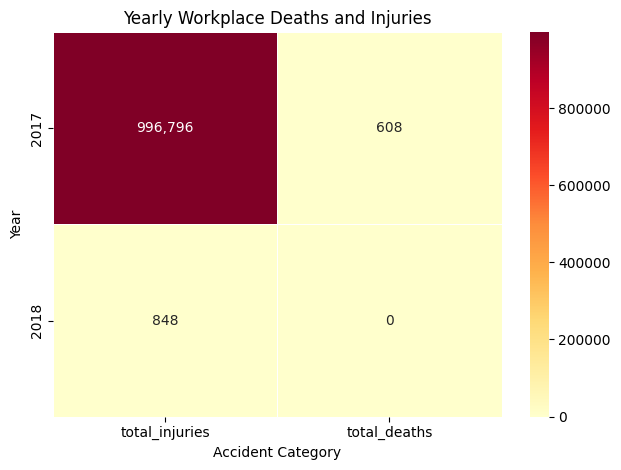

In [23]:
yearly_casual = df_clean.groupby(yearly).agg({'total_injuries' : 'sum', 'total_deaths' : 'sum'})
sns.heatmap(
    yearly_casual,
    annot=True,
    fmt=',.0f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Yearly Workplace Deaths and Injuries')
plt.xlabel('Accident Category')
plt.ylabel('Year')

plt.tight_layout()
plt.show()

On 2017 we suffered 996,796 injured casualties and 608 deaths are reported, a high number compared to 2018 where the total injuries were 848 with 0 deaths.

## 2. Which States have the most casualties?

Text(0, 0.5, 'Death')

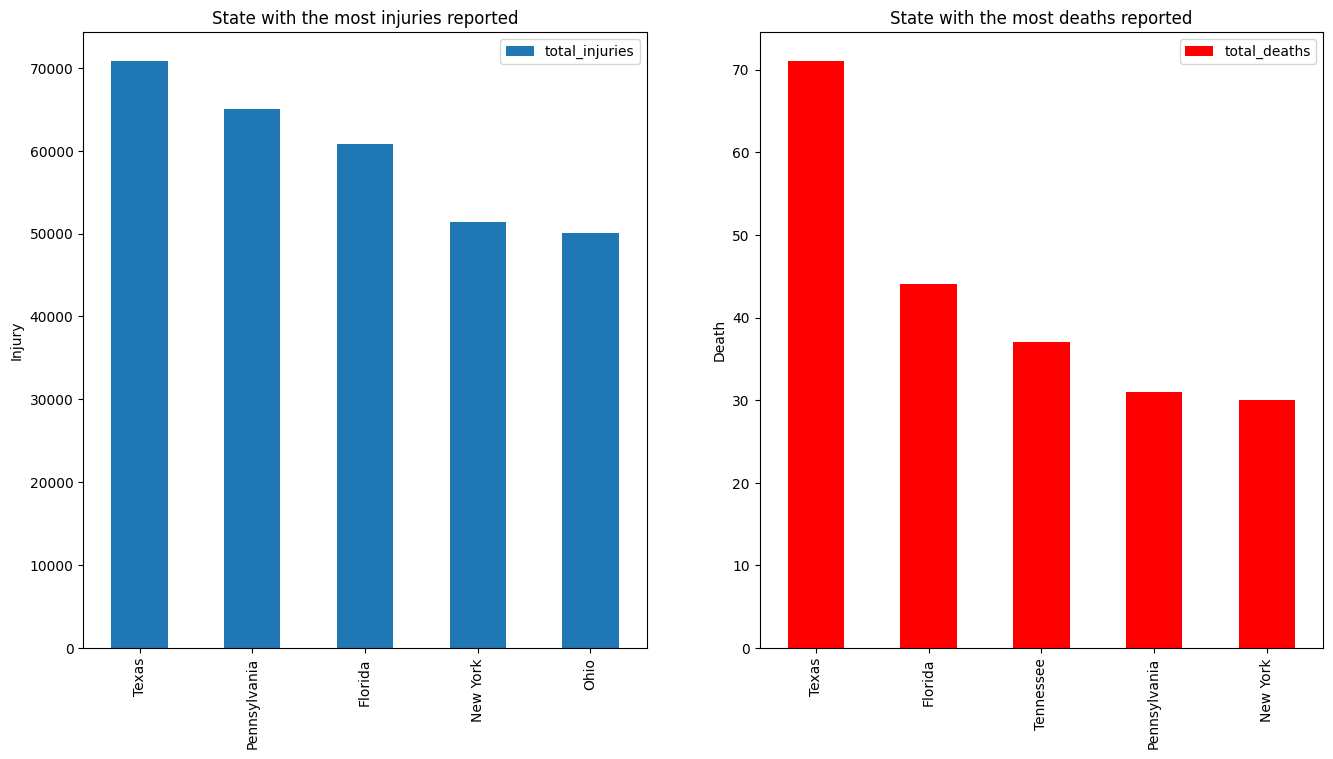

In [24]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16,8))

state_injury = df_clean.groupby('state').agg({'total_injuries' : 'sum'}).sort_values(by='total_injuries', ascending=False).head().plot(ax=ax[0], kind='bar')

state_death = df_clean.groupby('state').agg({'total_deaths' : 'sum'}).sort_values(by='total_deaths', ascending=False).head().plot(ax=ax[1], kind='bar', color='red')

ax[0].set_title('State with the most injuries reported')
ax[0].set_xlabel('')
ax[0].set_ylabel('Injury')

ax[1].set_title("State with the most deaths reported")
ax[1].set_xlabel('')
ax[1].set_ylabel('Death')



Analyzing measurement on casualties that resulted in death:

In [25]:
print(f'Mean: {df_clean["total_deaths"].mean()}')
print(f'Median: {df_clean["total_deaths"].median()}')
print(f'Mode: {df_clean["total_deaths"].mode().values[0]}')
print(f'Skewness: {df_clean["total_deaths"].skew()}')
print(f'SD: {df_clean["total_deaths"].std()}')

Mean: 0.002828196373582413
Median: 0.0
Mode: 0
Skewness: 26.229195252109886
SD: 0.05820406658902054


We know that casualties are have a small range, indicated by Standard deviation, with some high values

Analyzing measurement on casualties that resulted in injuries:

In [26]:
print(f'Mean: {df_clean["total_injuries"].mean()}')
print(f'Median: {df_clean["total_injuries"].median()}')
print(f'Mode: {df_clean["total_injuries"].mode().values[0]}')
print(f'Skewness: {df_clean["total_injuries"].skew()}')
print(f'SD: {df_clean["total_injuries"].std()}')

Mean: 4.6406795113918635
Median: 1.0
Mode: 0
Skewness: 82.00550080869218
SD: 21.75876526276778


## 3. Which Establishment has the most working hours?

In [27]:
most_hours = df_clean.groupby(['establishment_name']).agg({'total_hours_worked' : 'sum'})\
    .sort_values(by='total_hours_worked', ascending=False)
most_hours.head(10)

,total_hours_worked
establishment_name,
Rush University Medical Center,1655865404
Legend Oaks Health & Rehabilitation West San Antonio,1394815599
Pulaski Site,1289283332
Baptist Hospital,889453828
4718 Lakeland Correctional Facility,520000000
Kenover Marketing Corp,483711000
Century,428875490
Madcar,428875490
The Washington Hospital,367736778


With these information we could gain an important question:

`Does the amount of casualties also affected by establishment high working hours?`

In [28]:
est_report = df_clean.groupby('establishment_name').agg({'total_hours_worked' : 'sum', 'total_injuries' : 'sum', 'total_deaths' : 'sum'})\
.sort_values(by='total_hours_worked', ascending=False)
est_report.head(10)

,total_hours_worked,total_injuries,total_deaths
establishment_name,,,
Rush University Medical Center,1655865404,433,0
Legend Oaks Health & Rehabilitation West San Antonio,1394815599,4,0
Pulaski Site,1289283332,9,0
Baptist Hospital,889453828,176,0
4718 Lakeland Correctional Facility,520000000,4,0
Kenover Marketing Corp,483711000,2,0
Century,428875490,10,0
Madcar,428875490,3,0
The Washington Hospital,367736778,62,0


In [29]:
analysis_test = df_clean[['id','total_hours_worked']].copy()
analysis_test['total_casualties'] = df_clean['total_injuries'] + df_clean['total_deaths']
analysis_test.head()

,id,total_hours_worked,total_casualties
0,4,579688,6
1,5,501578,13
2,6,619945,18
3,7,75794,1
4,8,114734,6


In [30]:
r_casualties, p_casualties = pearsonr(
    analysis_test['total_hours_worked'],
    analysis_test['total_casualties']
)

print("Working Hours vs Casualties")
print(f"r = {r_casualties:.3f}")
print(f"p-value = {p_casualties:.4f}")

Working Hours vs Casualties
r = 0.142
p-value = 0.0000


## 4. Whose Establishment Responsible for the most casualties?

In [31]:
establishment_report = df_clean.groupby('establishment_type').agg({'total_injuries' : 'sum', 'total_deaths' : 'sum'})\
    .sort_values(by=['total_injuries','total_deaths'], ascending=False)

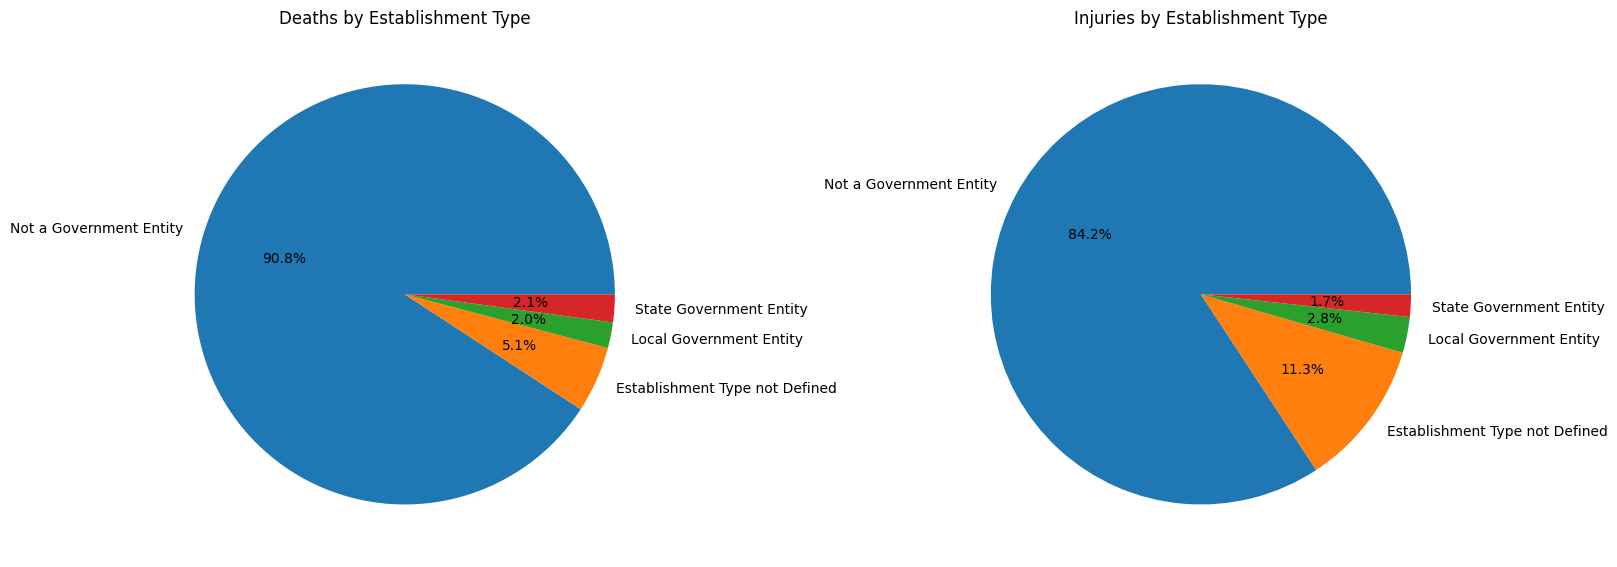

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Deaths
establishment_report['total_deaths'].plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[0]
)

axes[0].set_title('Deaths by Establishment Type')
axes[0].set_ylabel('')

# Injuries
establishment_report['total_injuries'].plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[1]
)

axes[1].set_title('Injuries by Establishment Type')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## 5. Which industry has the most reports?

In [33]:
most_rpt = df_clean.groupby('industry_description').size().reset_index(name='count').sort_values(by='count', ascending=False)

# vi. Conclusion

Conclusion: We can Reduce Casualties, by identifying which States, Companies, Establishment With a high casualties report, and conducting a regular monitoring on companies that has a large hours worked to identify potential risks.